# Fibre Bragg gratings: coupled modes, apodization, chirp and sensing

A fibre Bragg grating (FBG) is a periodic modulation of the core index,
written with ultraviolet light through a phase mask into a few millimetres
or centimetres of a photosensitive (GeO₂-doped) fibre. Each period reflects a
tiny part of the guided light; at the **Bragg wavelength**

$$
\lambda_B = 2n_{eff}\Lambda
$$

all the small reflections add in phase, and a grating of a few thousand
periods reflects nearly everything in a band a fraction of a nanometre wide
while passing all other wavelengths. It is the Bragg mirror of notebooks
10 (interfaces and thin films) to 14 (coated laser mirror), inside a fibre and with an index step a thousand times smaller.
FBGs stabilize lasers, separate wavelength channels, compensate dispersion
and measure strain and temperature.

1. the uniform grating: coupled mode theory against the thin film
   transfer matrix of `thin_films`,
2. nonuniform gratings by transfer matrices,
3. apodization: suppressing the side lobes,
4. chirped gratings that undo the dispersion of 20 km of fibre,
5. phase-shifted gratings and a WDM drop filter,
6. strain and temperature sensing.

The functions are in `pyoptics.fibres`: `fbg_uniform()` (analytic),
`fbg_transfer_matrix()` (piecewise uniform sections with apodization, chirp
and phase shifts), `fbg_delay()` and `bragg_shift()`. Wavelengths and
lengths are in µm (a 5 mm grating is 5000 µm), delays in ps.

In [1]:
import time

import numpy as np
import matplotlib.pyplot as plt

from pyoptics import fibres, fibrecomm as fc, thin_films, sketch

plt.rcParams.update({"figure.dpi": 80, "font.size": 11, "figure.facecolor": "white",
                     "axes.facecolor": "#fcfcfb", "savefig.facecolor": "white",
                     "axes.spines.top": False, "axes.spines.right": False})
BLUE, RED, GREEN, ORANGE, PURPLE, GREY = "#2a7ab9", "#d6604d", "#5aa469", "#e0a000", "#8e5ba8", "0.45"
t_start = time.time()

smf = fibres.smf28()
n_eff = float(fibres.effective_index(smf, 1.55))
lam_B = 1.55
period = lam_B/(2*n_eff)
print("LP01 of the SMF model at 1550 nm: n_eff = {:.5f}, grating period {:.2f} nm".format(n_eff, period*1E3))

LP01 of the SMF model at 1550 nm: n_eff = 1.44618, grating period 535.89 nm


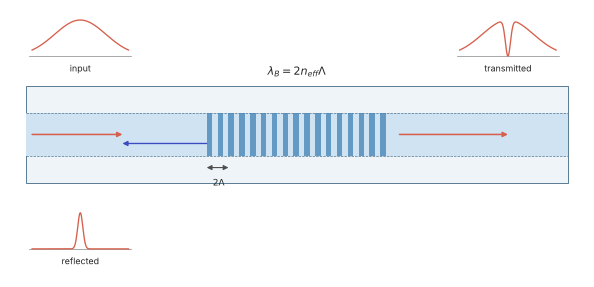

In [2]:
fig, ax = plt.subplots(figsize=(12, 4.4))
sketch.fibre_bragg_grating(ax)
plt.show()

## 1. The uniform grating

A grating $\delta n(z) = \delta n_{ac}\cos(2\pi z/\Lambda)$ (the modulation of
the effective index of the mode, i.e. the core modulation times the share
of the mode in the core) couples the forward and the backward core mode.
With the detuning $\hat\sigma = 2\pi n_{eff}/\lambda - \pi/\Lambda$ and the
coupling constant $\kappa = \pi\delta n_{ac}/\lambda$, coupled mode theory
(Erdogan) gives the reflection

$$
r = \frac{i\kappa\sinh(\gamma L)}{\gamma\cosh(\gamma L) - i\hat\sigma\sinh(\gamma L)}, \qquad
\gamma^2 = \kappa^2 - \hat\sigma^2,
$$

with the peak reflectivity $R = \tanh^2(\kappa L)$ at $\lambda_B$ and the
bandwidth between the first zeros

$$
\Delta\lambda_0 = \frac{\lambda_B^2}{\pi n_{eff}L}\sqrt{(\kappa L)^2 + \pi^2}.
$$

A weak grating ($\kappa L \ll 1$) has a sinc² spectrum whose width falls
with the length; a strong one saturates at 100 % and broadens to the
"band gap" $\Delta\lambda = \lambda_B\,\delta n_{ac}/n_{eff}$.

The thin film code of notebook 12 (layer stacks) solves the same problem exactly (a stack
of thousands of layers, eight per period, with the sinusoidal index of the
grating) and checks the coupled mode result.

κL = 0.5: peak R 0.2136 (tanh² 0.2136), zero-to-zero bandwidth 336 pm
κL = 1.0: peak R 0.5800 (tanh² 0.5800), zero-to-zero bandwidth 349 pm
κL = 2.0: peak R 0.9293 (tanh² 0.9293), zero-to-zero bandwidth 394 pm
κL = 4.0: peak R 0.9987 (tanh² 0.9987), zero-to-zero bandwidth 538 pm


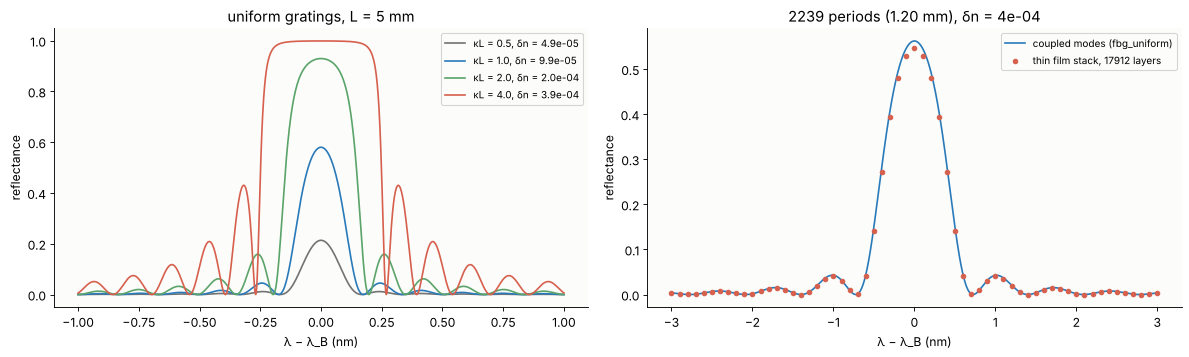

largest difference in R: 0.0169 (thin films: 10.8 s for 61 wavelengths)


In [3]:
wl = np.linspace(1.5490, 1.5510, 1601)
L = 5000.0
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
for kL, c in ((0.5, GREY), (1.0, BLUE), (2.0, GREEN), (4.0, RED)):
    dn = kL*lam_B/(np.pi*L)
    r, t = fibres.fbg_uniform(wl, L, n_eff, dn, period=period)
    axes[0].plot((wl - lam_B)*1E3, np.abs(r)**2, color=c, label=f"κL = {kL}, δn = {dn:.1e}")
    bw = lam_B**2/(np.pi*n_eff*L)*np.sqrt(kL**2 + np.pi**2)
    print("κL = {}: peak R {:.4f} (tanh² {:.4f}), zero-to-zero bandwidth {:.0f} pm".format(
          kL, np.max(np.abs(r)**2), np.tanh(kL)**2, bw*1E6))
axes[0].set_xlabel("λ − λ_B (nm)"); axes[0].set_ylabel("reflectance"); axes[0].legend(fontsize=9)
axes[0].set_title("uniform gratings, L = 5 mm")

# thin film check: a 1.2 mm grating with dn = 4e-4 as a stack
dn, N, sub = 4E-4, int(1200/period), 8
z = (np.arange(N*sub) + 0.5)/sub*period
n_stack = n_eff + dn*np.cos(2*np.pi*z/period)
d_stack = np.full(len(n_stack), period/sub)
wl_tf = np.linspace(1.5470, 1.5530, 61)
t0 = time.time()
r_tf = np.array([thin_films.r_t_coeffs(0.0, n_stack, 0*n_stack, d_stack, n_eff, 0, n_eff, 0, "s", w)[0]
                 for w in wl_tf])
t_tf = time.time() - t0
wl_f = np.linspace(1.5470, 1.5530, 1201)
r_cm, _ = fibres.fbg_uniform(wl_f, N*period, n_eff, dn, period=period)
axes[1].plot((wl_f - lam_B)*1E3, np.abs(r_cm)**2, color=BLUE, label="coupled modes (fbg_uniform)")
axes[1].plot((wl_tf - lam_B)*1E3, np.abs(r_tf)**2, "o", ms=4, color=RED,
             label=f"thin film stack, {len(n_stack)} layers")
axes[1].set_xlabel("λ − λ_B (nm)"); axes[1].set_ylabel("reflectance"); axes[1].legend(fontsize=9)
axes[1].set_title(f"{N} periods ({N*period/1E3:.2f} mm), δn = {dn:.0e}")
plt.tight_layout()
plt.show()
r_cm_tf, _ = fibres.fbg_uniform(wl_tf, N*period, n_eff, dn, period=period)
print("largest difference in R: {:.4f} (thin films: {:.1f} s for 61 wavelengths)".format(
      np.max(np.abs(np.abs(r_tf)**2 - np.abs(r_cm_tf)**2)), t_tf))

Coupled mode theory agrees with the exact layer calculation to about 1 %
in reflectance; the difference is the synchronous approximation (coupled
mode theory keeps only the resonant Fourier component of the grating and
neglects the non-resonant ones). For gratings in fibres, with
$\delta n \sim 10^{-4}$, it is excellent, and a thousand times faster.

## 2. Nonuniform gratings: transfer matrices

Real gratings are not uniform: their strength varies along the fibre
(apodization), their period may be chirped, and they may contain phase
jumps. The standard method (Yamada and Sakuda, Erdogan) cuts the grating
into sections short enough to be uniform, each with its own $2\times2$ transfer
matrix for the forward and backward amplitudes, and multiplies them.
`fibres.fbg_transfer_matrix()` does this for all wavelengths at once. For a
uniform grating it reproduces the analytic result to rounding.

In [4]:
z_edges = np.linspace(0, L, 101)
dn_u = 1.5*lam_B/(np.pi*L)
r_tm, _ = fibres.fbg_transfer_matrix(wl, z_edges, n_eff, period, dn_u)
r_an, _ = fibres.fbg_uniform(wl, L, n_eff, dn_u, period=period)
print("uniform grating in 100 sections: largest |r_TM - r_analytic| = {:.1e}".format(np.max(np.abs(r_tm - r_an))))

uniform grating in 100 sections: largest |r_TM - r_analytic| = 1.6e-15


## 3. Apodization

The side lobes of a uniform grating come from its abrupt ends, like the
side lobes of the Fourier transform of a rectangle (for weak gratings the
reflection *is* the Fourier transform of the coupling profile). A WDM
filter that must reject the neighbouring channel cannot have them. Tapering
$\delta n_{ac}(z)$ smoothly to zero at both ends (**apodization**) removes them.

There is a catch: UV writing raises the mean index too. If the mean index
change $\delta n_{dc}$ follows the apodization profile, the local Bragg
wavelength $2(n_{eff} + \delta n_{dc}(z))\Lambda$ is longer in the middle than
at the ends, the ends act as a weak Fabry–Perot for short wavelengths, and
the spectrum becomes asymmetric with lobes on the short side. Writing with
a constant mean index (the "DC-balanced" grating: the phase mask is
dithered or the fibre pre-exposed) avoids it.

uniform       : peak R 0.999, main lobe 288 pm wide, highest side lobe   -3.2 dB below the peak


Gaussian      : peak R 0.913, main lobe 682 pm wide, highest side lobe  -45.5 dB below the peak


raised cosine : peak R 0.955, main lobe 456 pm wide, highest side lobe  -33.1 dB below the peak


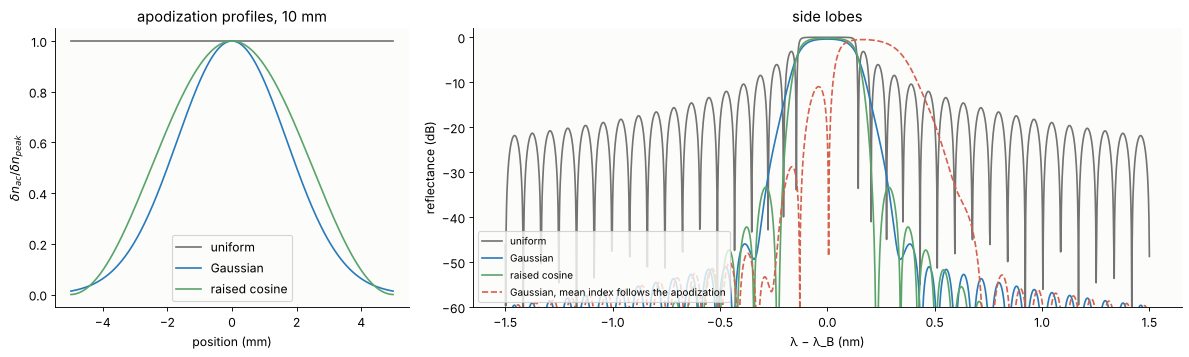

In [5]:
L_a = 10000.0
Ns = 300
z_edges = np.linspace(0, L_a, Ns + 1)
zc = (z_edges[1:] + z_edges[:-1])/2 - L_a/2
dn_peak = 2.2E-4
profiles = {"uniform": np.ones(Ns),
            "Gaussian": np.exp(-4*np.log(2)*(zc/(0.4*L_a))**2),
            "raised cosine": 0.5*(1 + np.cos(2*np.pi*zc/L_a))}
wl_a = np.linspace(1.5485, 1.5515, 1501)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6), gridspec_kw={"width_ratios": [1, 2]})
for (name, prof), c in zip(profiles.items(), (GREY, BLUE, GREEN)):
    axes[0].plot(zc/1E3, prof, color=c, label=name)
    r, _ = fibres.fbg_transfer_matrix(wl_a, z_edges, n_eff, period, dn_peak*prof)
    R = np.abs(r)**2
    axes[1].plot((wl_a - lam_B)*1E3, 10*np.log10(R + 1E-12), color=c, label=name)
    i0 = j = k = np.argmax(R)          # the main lobe ends at the first minima on both sides
    while j < len(R) - 1 and R[j + 1] < R[j]:
        j += 1
    while k > 0 and R[k - 1] < R[k]:
        k -= 1
    side = np.r_[R[:k], R[j + 1:]].max()
    print("{:14s}: peak R {:.3f}, main lobe {:.0f} pm wide, highest side lobe {:6.1f} dB below the peak".format(
          name, R.max(), (wl_a[j] - wl_a[k])*1E6, 10*np.log10(side/R.max())))
prof = profiles["Gaussian"]
r, _ = fibres.fbg_transfer_matrix(wl_a, z_edges, n_eff, period, dn_peak*prof, dn_dc=dn_peak*prof)
axes[1].plot((wl_a - lam_B)*1E3, 10*np.log10(np.abs(r)**2 + 1E-12), color=RED, ls="--",
             label="Gaussian, mean index follows the apodization")
axes[0].set_xlabel("position (mm)"); axes[0].set_ylabel(r"$\delta n_{ac}/\delta n_{peak}$"); axes[0].legend()
axes[0].set_title("apodization profiles, 10 mm")
axes[1].set_ylim(-60, 2)
axes[1].set_xlabel("λ − λ_B (nm)"); axes[1].set_ylabel("reflectance (dB)"); axes[1].legend(fontsize=9, loc="lower left")
axes[1].set_title("side lobes")
plt.tight_layout()
plt.show()

The strong uniform grating ($\kappa L = 4.5$) has its first side lobes only
3 dB below the saturated peak (a weak one would have the −13 dB of a sinc²).
The raised cosine profile pushes them to −33 dB, the Gaussian to −45 dB, at
the cost of a wider main band and a lower peak for the same maximum index
change. With the mean index following the
apodization (dashed) the short-wavelength side fills with resonances.

## 4. Chirped gratings and dispersion compensation

If the period changes along the grating, each wavelength is reflected at
its own position, and the reflected light is delayed by the round trip to
that position, $2n_{eff}z/c$. A linear chirp gives a group delay that changes
linearly with the wavelength: a dispersion in ps/nm, of either sign,
concentrated in a few centimetres.

20 km of standard fibre at 1550 nm accumulate $DL = 17.6 \times 20 \approx 350$
ps/nm: longer wavelengths arrive later. To undo this over a 1 nm band, the
grating must delay the short wavelengths by 350 ps more than the long ones,
so the short wavelengths are reflected at the far end and the period
*decreases* along the grating. 350 ps of round trip take a grating of
$350\,\mathrm{ps}\cdot c/(2n_{eff}) = 36$ mm. Its ends are apodized over 5 mm
to reduce the ripple of the delay.

grating length 36.5 mm, dispersion -372 ps/nm (fibre: +353 ps/nm), delay ripple ±7.9 ps


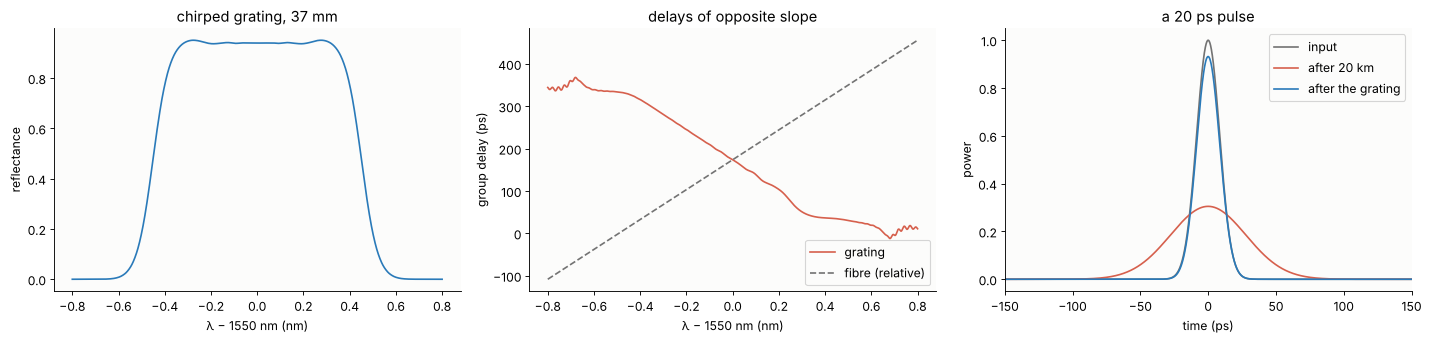

input             : rms width    8.5 ps, energy 1.000
after the fibre   : rms width   27.8 ps, energy 1.000
after the grating : rms width    8.6 ps, energy 0.937


In [6]:
D = float(fibres.dispersion(smf, 1.55))
L_fibre = 20.0
DL = D*L_fibre                                  # ps/nm of the fibre
band = 1.0E-3                                   # 1 nm in µm
L_g = DL*band*1E3*fibres.C_UM_PER_PS/(2*n_eff)  # µm
Ns = 1200
z_edges = np.linspace(0, L_g, Ns + 1)
zc = (z_edges[1:] + z_edges[:-1])/2
lam_local = lam_B + band*(0.5 - zc/L_g)         # long wavelengths near the input
per = lam_local/(2*n_eff)
edge = 5000.0
apod = np.clip(np.minimum(zc, L_g - zc)/edge, 0, 1)
apod = np.sin(np.pi/2*apod)**2
wl_c = np.linspace(lam_B - 0.8E-3, lam_B + 0.8E-3, 1601)
r_c, _ = fibres.fbg_transfer_matrix(wl_c, z_edges, n_eff, per, 1.5E-4*apod)
tau, dtau = fibres.fbg_delay(wl_c, r_c)
sel = np.abs(wl_c - lam_B) < 0.35E-3
slope = np.polyfit((wl_c[sel] - lam_B)*1E3, tau[sel], 1)
ripple = tau[sel] - np.polyval(slope, (wl_c[sel] - lam_B)*1E3)
print("grating length {:.1f} mm, dispersion {:.0f} ps/nm (fibre: +{:.0f} ps/nm), delay ripple ±{:.1f} ps".format(
      L_g/1E3, slope[0], DL, np.ptp(ripple)/2))

fig, axes = plt.subplots(1, 3, figsize=(18, 4.4))
axes[0].plot((wl_c - lam_B)*1E3, np.abs(r_c)**2, color=BLUE)
axes[0].set_xlabel("λ − 1550 nm (nm)"); axes[0].set_ylabel("reflectance"); axes[0].set_title(f"chirped grating, {L_g/1E3:.0f} mm")
axes[1].plot((wl_c - lam_B)*1E3, tau, color=RED, label="grating")
axes[1].plot((wl_c - lam_B)*1E3, tau[np.argmin(abs(wl_c - lam_B))] + DL*(wl_c - lam_B)*1E3, color=GREY,
             ls="--", label="fibre (relative)")
axes[1].set_xlabel("λ − 1550 nm (nm)"); axes[1].set_ylabel("group delay (ps)"); axes[1].legend()
axes[1].set_title("delays of opposite slope")

# a 10 Gb/s-like pulse: through 20 km of fibre, then reflected by the grating
t = np.linspace(-600, 600, 8192, endpoint=False)
T0 = 12.0
A0 = fc.gaussian_pulse(t, T0)
A1 = fc.propagate(t, A0, L_fibre, fibres.beta2_from_D(D, 1550))
W = 2*np.pi*np.fft.fftfreq(len(t), t[1] - t[0])          # rad/ps, exp(-i W t) components
wl_of_W = 2*np.pi*fibres.C_UM_PER_PS/(2*np.pi*fibres.C_UM_PER_PS/lam_B + W)
r_W = np.interp(wl_of_W, wl_c, r_c.real) + 1j*np.interp(wl_of_W, wl_c, r_c.imag)
A2 = np.fft.fft(np.fft.ifft(A1)*r_W)
A2 = np.roll(A2, -np.argmax(np.abs(A2)) + np.argmax(np.abs(A0)))
for A, name, c in ((A0, "input", GREY), (A1, f"after {L_fibre:.0f} km", RED), (A2, "after the grating", BLUE)):
    axes[2].plot(t, np.abs(A)**2, color=c, label=name)
axes[2].set_xlim(-150, 150); axes[2].set_xlabel("time (ps)"); axes[2].set_ylabel("power")
axes[2].set_title(f"a {1.665*T0:.0f} ps pulse"); axes[2].legend()
plt.tight_layout()
plt.show()
for A, name in ((A0, "input"), (A1, "after the fibre"), (A2, "after the grating")):
    P = np.abs(A)**2
    m = np.sum(P*t)/np.sum(P)
    print("{:18s}: rms width {:6.1f} ps, energy {:.3f}".format(name, np.sqrt(np.sum(P*(t - m)**2)/np.sum(P)),
                                                             np.sum(P)/np.sum(np.abs(A0)**2)))

The grating restores the pulse to nearly its input width. Its dispersion
comes out about 5 % larger than designed (a wavelength is reflected a little
before the point where it matches the local period), and the delay has a
ripple of several ps from the reflections of the weak grating ends. Both
leave a small residual. Chirped FBGs compete
with dispersion compensating fibre (a fibre with large negative D, many
kilometres of it, with extra loss); their strength is the small size and
the low loss, their weakness the limited bandwidth (one channel or a band of
a few nm per grating, or very long gratings) and the ripple.

## 5. Phase-shifted gratings and a WDM drop filter

A jump of the grating phase by $\pi$ in the middle turns the grating into two
Bragg mirrors a quarter wave apart: a Fabry–Perot resonator with a single
resonance in the middle of the stop band. The transmission shows a
line a few pm wide: the cavity of DFB fibre lasers and of narrow filters.

For wavelength division multiplexing, channels sit on the ITU grid,
100 GHz (0.8 nm) apart around 193.1 THz. An apodized grating with a
0.4 nm wide flat band reflects one channel ("drops" it to a circulator) and
passes the others. The figure of merit is the isolation: how little of the
neighbouring channels is reflected.

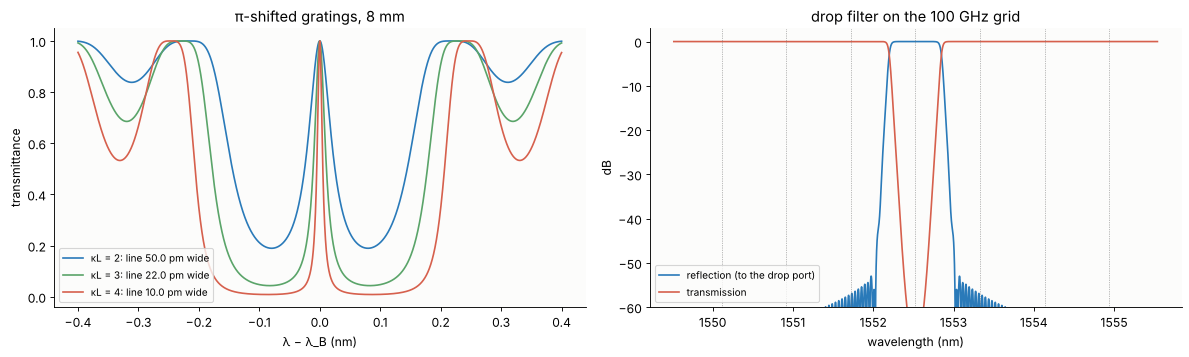

drop channel 1552.52 nm: reflected 1.0000; neighbours reflected -62.0 and -62.0 dB


In [7]:
fig, axes = plt.subplots(1, 2, figsize=(15, 4.6))
L_p = 8000.0
z_edges = np.linspace(0, L_p, 401)
wl_p = np.linspace(lam_B - 0.4E-3, lam_B + 0.4E-3, 4001)
for kL, c in ((2.0, BLUE), (3.0, GREEN), (4.0, RED)):
    dn = kL*lam_B/(np.pi*L_p)
    r, t_ = fibres.fbg_transfer_matrix(wl_p, z_edges, n_eff, period, dn, phase_shifts={200: np.pi})
    T = np.abs(t_)**2
    peak = np.abs(wl_p - lam_B) < 0.05E-3
    half = wl_p[peak][T[peak] > 0.5*T[peak].max()]
    axes[0].plot((wl_p - lam_B)*1E3, T, color=c, label=f"κL = {kL:.0f}: line {np.ptp(half)*1E6:.1f} pm wide")
axes[0].set_xlabel("λ − λ_B (nm)"); axes[0].set_ylabel("transmittance"); axes[0].legend(fontsize=9)
axes[0].set_title("π-shifted gratings, 8 mm")

f_grid = 193.1 + 0.1*np.arange(-3, 4)              # THz
lam_grid = 2.99792458E5/f_grid*1E-3                 # µm (vacuum)
lam_drop = lam_grid[3]
L_d = 20000.0
Ns = 400
z_edges = np.linspace(0, L_d, Ns + 1)
zc = (z_edges[1:] + z_edges[:-1])/2 - L_d/2
apod = np.exp(-4*np.log(2)*(zc/(0.35*L_d))**2)
# a flat-topped band: a slightly chirped, strong, apodized grating
per_d = (lam_drop + 0.25E-3*zc/L_d)/(2*n_eff)
wl_d = np.linspace(lam_grid[-1] - 0.6E-3, lam_grid[0] + 0.6E-3, 6001)
r_d, _ = fibres.fbg_transfer_matrix(wl_d, z_edges, n_eff, per_d, 6E-4*apod)
R_d = np.abs(r_d)**2
axes[1].plot(wl_d*1E3, 10*np.log10(R_d + 1E-9), color=BLUE, label="reflection (to the drop port)")
axes[1].plot(wl_d*1E3, 10*np.log10(np.maximum(1 - R_d, 1E-9)), color=RED, label="transmission")
for lg in lam_grid:
    axes[1].axvline(lg*1E3, color=GREY, lw=0.6, ls=":")
axes[1].set_ylim(-60, 3); axes[1].set_xlabel("wavelength (nm)"); axes[1].set_ylabel("dB")
axes[1].set_title("drop filter on the 100 GHz grid"); axes[1].legend(fontsize=9, loc="lower left")
plt.tight_layout()
plt.show()
R_at = np.interp(lam_grid, wl_d, R_d)
print("drop channel {:.2f} nm: reflected {:.4f}; neighbours reflected {:.1f} and {:.1f} dB".format(
      lam_drop*1E3, R_at[3], 10*np.log10(R_at[2]), 10*np.log10(R_at[4])))

## 6. Sensing: strain and temperature

Stretching the fibre changes both the period and, through the
photo-elastic effect, the index; heating it expands the glass and raises
its index. Both shift the Bragg wavelength (`fibres.bragg_shift()`):

$$
\frac{\Delta\lambda_B}{\lambda_B} = (1 - p_e)\,\varepsilon + (\alpha + \xi)\,\Delta T,
$$

with the effective photo-elastic constant $p_e \approx 0.22$, the thermal
expansion $\alpha = 0.55\cdot10^{-6}$/K and the thermo-optic coefficient
$\xi \approx 6.7\cdot10^{-6}$/K: about 1.2 pm per microstrain and 11 pm per
kelvin at 1550 nm. Many gratings at different wavelengths along one fibre
read out by one broadband source and a spectrometer form a quasi-distributed
sensor for bridges, aircraft wings and pipelines. Because strain and
temperature both shift the line, a strain sensor needs a strain-free
reference grating next to it (or two gratings with different sensitivities).

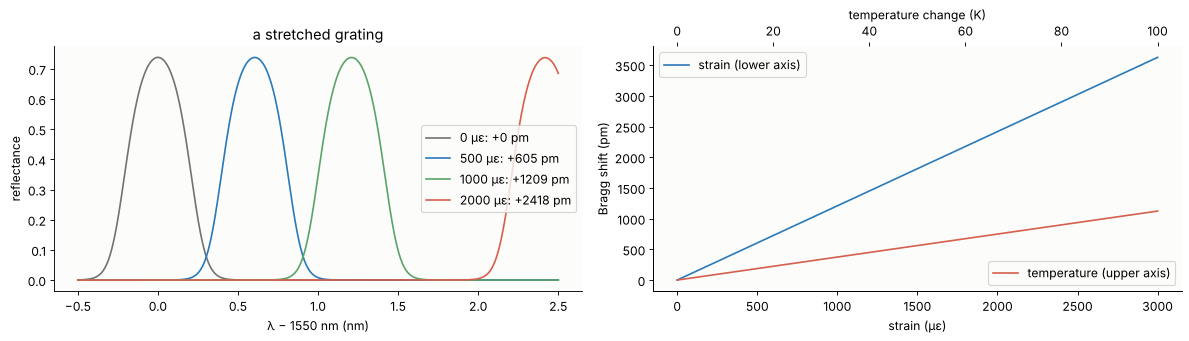

sensitivity at 1550 nm: 1.209 pm/µε, 11.2 pm/K


In [8]:
L_s = 5000.0
z_edges = np.linspace(0, L_s, 201)
zc = (z_edges[1:] + z_edges[:-1])/2 - L_s/2
apod = np.exp(-4*np.log(2)*(zc/(0.4*L_s))**2)
wl_s = np.linspace(1.5495, 1.5525, 3001)
fig, axes = plt.subplots(1, 2, figsize=(15, 4.4))
for strain, c in ((0, GREY), (500E-6, BLUE), (1000E-6, GREEN), (2000E-6, RED)):
    shift = fibres.bragg_shift(lam_B, strain=strain)
    per_s = (lam_B + shift)/(2*n_eff)
    r, _ = fibres.fbg_transfer_matrix(wl_s, z_edges, n_eff, per_s, 3E-4*apod)
    axes[0].plot((wl_s - lam_B)*1E3, np.abs(r)**2, color=c, label=f"{strain*1E6:.0f} µε: +{shift*1E6:.0f} pm")
axes[0].set_xlabel("λ − 1550 nm (nm)"); axes[0].set_ylabel("reflectance"); axes[0].legend()
axes[0].set_title("a stretched grating")
eps = np.linspace(0, 3000, 31)*1E-6
dT = np.linspace(0, 100, 31)
axes[1].plot(eps*1E6, fibres.bragg_shift(1550.0, strain=eps)*1E3, color=BLUE, label="strain (lower axis)")
ax2 = axes[1].twiny()
ax2.plot(dT, fibres.bragg_shift(1550.0, dT=dT)*1E3, color=RED, label="temperature (upper axis)")
axes[1].set_xlabel("strain (µε)"); ax2.set_xlabel("temperature change (K)")
axes[1].set_ylabel("Bragg shift (pm)")
axes[1].legend(loc="upper left"); ax2.legend(loc="lower right")
plt.tight_layout()
plt.show()
print("sensitivity at 1550 nm: {:.3f} pm/µε, {:.1f} pm/K".format(
      fibres.bragg_shift(1550.0, strain=1E-6)*1E3, fibres.bragg_shift(1550.0, dT=1.0)*1E3))

A shift of 1 pm, easily resolved by an interrogator, is a microstrain or
a tenth of a kelvin.

## Summary

- **Bragg condition** $\lambda_B = 2n_{eff}\Lambda$: a period of 536 nm for
  1550 nm in the SMF model.
- **Uniform grating:** $R = \tanh^2(\kappa L)$, bandwidth
  $\lambda_B^2\sqrt{(\kappa L)^2 + \pi^2}/(\pi n_{eff}L)$; coupled mode theory
  agrees with a 17 000-layer thin film stack to about 1 % in R.
- **Transfer matrices** of short uniform sections handle apodization, chirp
  and phase shifts (`fbg_transfer_matrix()`); exact for uniform gratings.
- **Apodization** pushes side lobes from −3 dB (strong uniform grating) to
  −33 dB (raised cosine) and −45 dB (Gaussian), if the
  mean index stays constant.
- **Chirp:** a 36 mm grating with about −370 ps/nm compensates 20 km of
  standard fibre (+353 ps/nm) for a 1 nm band and restores a 20 ps pulse.
- **π shift:** a transmission line of a few pm in the stop band.
  **Drop filter:** an apodized grating isolates a 100 GHz channel by more
  than 50 dB from its neighbours in this ideal model (real filters reach 25
  to 40 dB, limited by errors in the writing).
- **Sensing:** 1.2 pm/µε and 11 pm/K at 1550 nm.

In [9]:
print("run time: {:.0f} s".format(time.time() - t_start))

run time: 15 s


## References

- T. Erdogan, "Fiber grating spectra", J. Lightwave Technol. 15,
  1277–1294 (1997).
- M. Yamada and K. Sakuda, "Analysis of almost-periodic distributed
  feedback slab waveguides via a fundamental matrix approach", Appl. Opt.
  26, 3474–3478 (1987).
- A. Othonos, "Fiber Bragg gratings", Rev. Sci. Instrum. 68, 4309–4341
  (1997).
- R. Kashyap, *Fiber Bragg Gratings*, 2nd ed., Academic Press (2010).
- K. O. Hill and G. Meltz, "Fiber Bragg grating technology fundamentals
  and overview", J. Lightwave Technol. 15, 1263–1276 (1997).
- F. Ouellette, "Dispersion cancellation using linearly chirped Bragg
  grating filters in optical waveguides", Opt. Lett. 12, 847–849 (1987).
- ITU-T G.694.1 (DWDM frequency grid).